## Debugging Question 1
import seaborn as sns
import numpy as np
import pandas as pd

data = pd.DataFrame({
    'Age': [25, 30, 35, 40, 45],
    'BMI': [22.4, 23.0, 25.5, 26.0, 28.3],
    'Blood_Pressure': [120, 122, 124, 130, 135]
})

correlation_matrix = np.corr(data)
sns.heatmap(correlation_matrix, annot=True)


In [2]:
import seaborn as sns
import numpy as np
import pandas as pd

data = pd.DataFrame({
    'Age': [25, 30, 35, 40, 45],
    'BMI': [22.4, 23.0, 25.5, 26.0, 28.3],
    'Blood_Pressure': [120, 122, 124, 130, 135]
})

correlation_matrix = np.corr(data)
sns.heatmap(correlation_matrix, annot=True)


AttributeError: module 'numpy' has no attribute 'corr'

                     Age       BMI  Blood_Pressure
Age             1.000000  0.978182        0.972125
BMI             0.978182  1.000000        0.951253
Blood_Pressure  0.972125  0.951253        1.000000


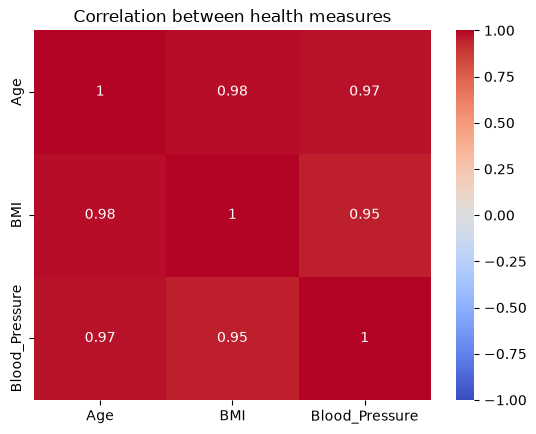

In [1]:
# The correlation must be calculated between columns, not across DataFrame rows.
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

data = pd.DataFrame({'Age':[25,30,35,40,45], 'BMI':[22.4,23.0,25.5,26.0,28.3], 'Blood_Pressure':[120,122,124,130,135]})
correlation_matrix=data.corr(numeric_only=True)
print(correlation_matrix)
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',vmin=-1,vmax=1)
plt.title('Correlation between health measures');plt.show()

## Debugging Question 2

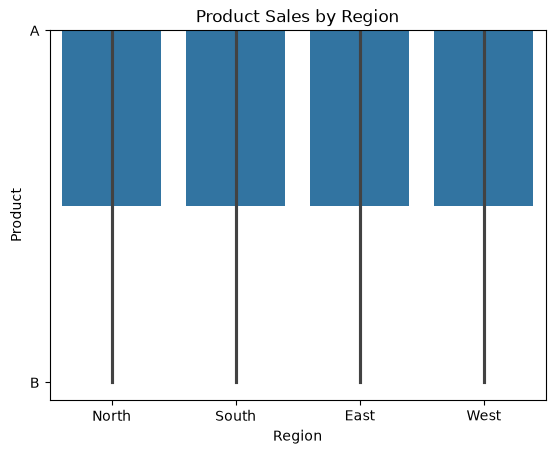

In [4]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({
    'Region': ['North', 'South', 'East', 'West', 'North', 'South', 'East', 'West'],
    'Product': ['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B'],
    'Sales': [200, 220, 250, 240, 180, 210, 230, 220]
})

sns.barplot(x='Region', y='Product', data=data)
plt.title('Product Sales by Region')
plt.show()

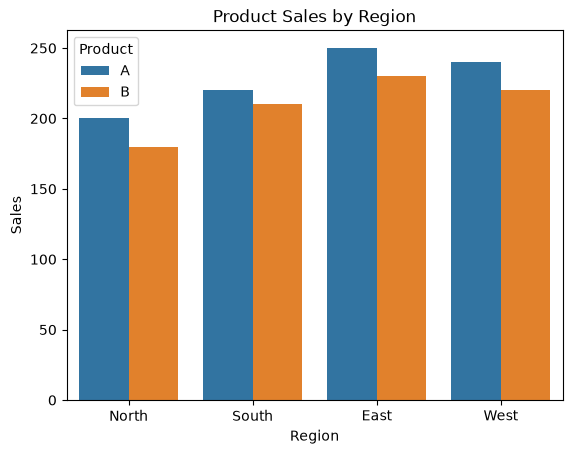

In [3]:
# Region and Product are categories. Sales is the numeric value to compare.
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

data=pd.DataFrame({'Region':['North','South','East','West','North','South','East','West'],'Product':['A','A','A','A','B','B','B','B'],'Sales':[200,220,250,240,180,210,230,220]})
sns.barplot(data=data,x='Region',y='Sales',hue='Product',errorbar=None)
plt.title('Product Sales by Region');plt.show()

## Debugging Question 3

**Original code:**
```python
import pandas as pd

data = pd.DataFrame({
    'Transaction': [1, 2, 3, 4, 5],
    'Amount': [100, 200, None, 400, 500],
    'Fraud': [0, 1, 0, 1, 0]
})

data['Amount'].fillna('Missing', inplace=True)
mean_value = data['Amount'].mean()
print(f"Mean Transaction Amount: {mean_value}")


In [5]:
# Replacing a number with the text 'Missing' prevents numeric calculations.
import pandas as pd

data=pd.DataFrame({'Transaction':[1,2,3,4,5],'Amount':[100,200,None,400,500],'Fraud':[0,1,0,1,0]})
data['Amount']=data['Amount'].fillna(data['Amount'].median())
print(data)
print(f"Mean Transaction Amount: {data['Amount'].mean():.2f}")

   Transaction  Amount  Fraud
0            1   100.0      0
1            2   200.0      1
2            3   300.0      0
3            4   400.0      1
4            5   500.0      0
Mean Transaction Amount: 300.00


## Debugging Question 4

**Original code:**
```python
import pandas as pd
import numpy as np

data = pd.DataFrame({'Values': [10, 12, 15, 18, 120, 14, 13, 16, 17, 150]})

Q1 = data['Values'].quantile(0.25)
Q3 = data['Values'].quantile(0.75)

filtered_data = data[(data['Values'] < Q1 - 1.5 * IQR) | (data['Values'] > Q3 + 1.5 * IQR)]

print("Filtered Data without Outliers:")
print(filtered_data)


In [6]:
# Calculate IQR before using it; retain the rows INSIDE the limits.
import pandas as pd

data=pd.DataFrame({'Values':[10,12,15,18,120,14,13,16,17,150]})
q1=data['Values'].quantile(.25);q3=data['Values'].quantile(.75);iqr=q3-q1
lower=q1-1.5*iqr;upper=q3+1.5*iqr
filtered_data=data[data['Values'].between(lower,upper)]
print('Filtered Data without Outliers:')
print(filtered_data)
print('Detected outliers:',data[~data['Values'].between(lower,upper)]['Values'].tolist())

Filtered Data without Outliers:
   Values
0      10
1      12
2      15
3      18
5      14
6      13
7      16
8      17
Detected outliers: [120, 150]


## Debugging Question 5

**Original code:**
```python
import pandas as pd
from scipy import stats

data = pd.DataFrame({
    'Region': ['North', 'South', 'East', 'West', 'North', 'South', 'East', 'West'],
    'Sales': [200, 220, 250, 240, 180, 210, 230, 220]
})

north_sales = data[data['Region'] == 'North']['Sales']
south_sales = data[data['Region'] == 'South']['Sales']
east_sales = data[data['Region'] == 'East']['Sales']
west_sales = data[data['Region'] == 'West']['Sales']

f_stat, p_value = stats.f_oneway(north_sales, south_sales, east_sales, west_sales)
print(f"F-Statistic: {f_stat}, P-Value: {p_value}")


In [7]:
# ANOVA tests whether mean sales differ across the four regions.
# The original code is valid; add a decision and note the small sample size.
import pandas as pd
from scipy import stats

data=pd.DataFrame({'Region':['North','South','East','West','North','South','East','West'],'Sales':[200,220,250,240,180,210,230,220]})
groups=[group['Sales'].to_numpy() for _,group in data.groupby('Region')]
f_stat,p_value=stats.f_oneway(*groups)
print(f'F-Statistic: {f_stat:.4f}, P-Value: {p_value:.4f}')
print('Significant difference at 5% level' if p_value<.05 else 'Not enough evidence of a difference at 5% level')
print('Note: Only two observations per region; interpret the result cautiously.')

F-Statistic: 5.8205, P-Value: 0.0609
Not enough evidence of a difference at 5% level
Note: Only two observations per region; interpret the result cautiously.
